# Problem 1 — Distributed pipeline parallelism

**NYU · CSCI-GA 3033-091 · INTRO TO LLM BASED GENERATIVE AI SYSTEMS**
**Homework 2 · Due October 16, 2026 · 25 points**
Instructors: Parijat Dube (`pd2216@nyu.edu`), Chen Wang (`cw4824@nyu.edu`)
TAs: Raj Appana (`sa9026@nyu.edu`), Satyapragnya Kar (`sk13001@nyu.edu`)

Rubric: concepts **5** (bubbles 3, interleaving 2), setup/implementation **4**,
experiments **10**, speedup/efficiency **4**, discussion **2**.

Start with the [official PyTorch tutorial](https://docs.pytorch.org/tutorials/intermediate/pipelining_tutorial.html)
and [pipeline API](https://docs.pytorch.org/docs/stable/distributed.pipelining.html).
The tutorial's actual [RST source](https://github.com/pytorch/tutorials/blob/main/intermediate_source/pipelining_tutorial.rst)
contains the reusable API examples, not a verified downloadable notebook pair.
Our API workflow adapts that BSD-3-Clause material; see the complete BSD notice embedded at the end of this notebook.
The causal batch-first model, experiment grid and notebook exercises are assignment-specific.

**Student starter — complete every TODO.**

## 1. Concepts — 5 points

1. **Bubbles (3):** What makes a rank idle? Compare GPipe, synchronous 1F1B,
   and Interleaved1F1B. Give a quantitative idealization and state its assumptions.
   distinguish activation-memory savings from bubble savings.
2. **Interleaving (2):** Explain multiple virtual stages per rank, the ownership
   mapping, and when its shorter chunks help or communication costs dominate.

**TODO:** Write technical answers to questions 1 and 2 here.

### Answers to the concept questions

**1. Bubbles: what makes a rank idle, and how GPipe, 1F1B and Interleaved1F1B compare.**

*What makes a rank idle.* In a synchronous pipeline, a rank is idle (a "bubble") whenever it has no ready work:
- **Fill:** at the start, stage *k* waits for the forward activations of the first micro-batch to pass through stages 0…k−1.
- **Drain:** at the end, early stages wait for the backward gradients to come back from later stages.
- **During the step:** a rank also stalls when its neighbours are slower (unequal stage costs), or while waiting for point-to-point communication.

The step ends with a flush, which is a synchronisation point before the optimizer update, so these fill and drain bubbles occur at every training iteration.

*Idealisation.* Assume:
- P stages, one per rank, and m equal micro-batches;
- every stage takes the same time t_f forward and t_b backward per micro-batch;
- communication is free or fully overlapped;
- the optimizer step is negligible;
- devices are identical and m is divisible by P.

| Schedule | Order of work | Bubble time per step | Bubble overhead vs ideal m(t_f+t_b) | In-flight activations per rank |
|---|---|---|---|---|
| **GPipe** | all m forwards, then all m backwards | (P−1)(t_f+t_b) | (P−1)/m | **m** micro-batches |
| **1F1B** (synchronous, PipeDream-flush) | P−r warm-up forwards, then alternate one forward/one backward, then drain | (P−1)(t_f+t_b) | (P−1)/m (same as GPipe) | **≤ P** micro-batches |
| **Interleaved1F1B** (v virtual stages per rank; v = 2 here) | 1F1B over v·P smaller chunks | (P−1)(t_f+t_b)/v | (P−1)/(v·m) | about P (plus extra in-flight chunks) |

*For this assignment (m = 8).*
- Bubble overhead (P−1)/m: **P = 2 → 12.5%**, **P = 4 → 37.5%** for GPipe and 1F1B; **6.25% and 18.75%** for Interleaved1F1B with v = 2.
- Equivalently, the idle fraction of the whole step, (P−1)/(m+P−1), is 11.1% and 27.3% for GPipe/1F1B, and (P−1)/(v·m+P−1) gives 5.9% and 15.8% for interleaving.

*Bubble savings versus memory savings.*
- **1F1B does not reduce the bubble** relative to GPipe. Its benefit is **activation memory**: each rank keeps at most about P micro-batches of saved activations instead of all m, so memory no longer grows with the number of micro-batches.
- **Interleaving reduces the bubble itself**, because fill and drain consist of chunks 1/v as long. It pays for this with more communication.

*Caveat.* In practice t_b ≈ 2t_f, stage costs are unequal, and communication is not free, so measured times deviate from these formulas.

**2. Interleaving: virtual stages, ownership and when it helps.**

- *Virtual stages.* The model is cut into v·P consecutive chunks (virtual stages) instead of P. Each rank owns v of them, assigned round-robin: **rank r owns stages r, r+P, …, r+(v−1)P**.
  - Here v = 2, so rank r owns stages r and r+P. On 4 ranks with 8 stages: rank 0 → {0, 4}, rank 1 → {1, 5}, rank 2 → {2, 6}, rank 3 → {3, 7}.
  - A micro-batch therefore loops through the ring of ranks v times, forward and backward.
  - In this notebook every layer is split into an attention half and an MLP half. This gives 2L residual units, so even the 4-layer model has 8 real stages on 4 ranks.
- *Why shorter chunks help.* Each chunk does 1/v of a rank's work. The first useful backward reaches a rank sooner, and fill and drain take (P−1)·(t_f+t_b)/v instead of (P−1)·(t_f+t_b), so the bubble shrinks by a factor of v.
  - This matters most when the bubble is large relative to the step: **many ranks P and few micro-batches m**.
  - It also needs the per-chunk compute to stay well above the communication latency: large layers or micro-batches, and a fast interconnect such as NVLink.
- *When communication dominates.* Interleaving multiplies point-to-point transfers. Each micro-batch crosses v·P−1 stage boundaries instead of P−1, in both directions, and each transfer has a fixed latency plus scheduling and Python overhead.
  - When chunks are small (small width, short sequences, small micro-batches), on slow transports (CPU with Gloo, PCIe or network), or with an imbalanced partition, the extra transfers cost more than the bubble they save.
  - In that case interleaving can be **slower** than GPipe or 1F1B.
  - It also keeps more chunks in flight, which uses more activation memory than plain 1F1B, and PyTorch requires m to be divisible by P.

## 2. Setup and implementation — 4 points

Upload **only this `.ipynb`** with Colab **File → Upload notebook**, select a
CPU runtime, and run setup cells in order. No `.py`/requirements upload, clone,
credentials or particular working directory is needed. Local Jupyter also works.
The standard-library bootstrap creates a private temporary workspace for this
problem and student/reference variant; reruns reuse it without changing cwd.
The visible ungraded export writes the bundled worker there, followed by your
graded task export. Do not create a distributed process group inside Jupyter.

**Dependencies:** PyTorch **2.10+** with distributed support (2.10 is the tested
API), pandas and matplotlib. The installer checks metadata before importing ML
libraries and preserves a compatible installed Torch/vision/audio stack. If
incompatible, it stops without changing it. Only if you explicitly enable
`REPAIR_TORCH_STACK` does it install the coordinated 2.10.0/0.25.0/2.10.0 trio.
After any installation, **restart the runtime/kernel**, reset the repair flag to
False, and rerun from the top; do not continue using loaded binary packages.
An API/Gloo check follows installation; newer versions are not a tested guarantee.

`pipeline_worker.py` provides a small decoder-only, causal Transformer using
pre-normalized attention/MLP residual units, learned positions, untied token/output
weights and zero dropout. Splitting each layer into attention/MLP halves allows
**four layers on four ranks with eight real virtual stages**, without dummy stages.
This is not an equal-cost partition: attention, MLP, embedding and head cost differ.
Each rank retains only its local modules before timing.

The graded export cell below owns partition/schedule selection, the 54-case grid,
experiment orchestration and metric analysis. The worker owns only the model,
shape examples, synthetic data, timed distributed loop, persistence and launcher.
Both `input_args` and `output_args` are passed to `PipelineStage` (avoids the
deprecated input-only initialization). All ranks participate; only the first
stage consumes input IDs and only the last consumes targets/collects losses.

**Record here:** OS/CPU, PyTorch/Python/CUDA versions, GPU model/count, memory,
interconnect, kernel path and any setup steps. CPU/Gloo smoke tests establish
correctness, **not** multi-GPU performance. A CUDA benchmark needs four visible
GPUs for the complete grid; each process uses `LOCAL_RANK` and NCCL.

Runtime storage is ephemeral. Save the notebook and use the optional result archive/download cell before disconnecting; no Drive mount is required.

In [1]:
# Standard library only; safe before dependency setup and on cell reruns.
from pathlib import Path
import tempfile

_HW2_WORKSPACES = globals().setdefault("_HW2_WORKSPACES", {})
P1_student = "student"
P1_WORKSPACE_KEY = ("problem1", P1_student)
if P1_WORKSPACE_KEY not in _HW2_WORKSPACES:
    _HW2_WORKSPACES[P1_WORKSPACE_KEY] = Path(
        tempfile.mkdtemp(prefix=f"hw2-p1-{P1_student}-")).resolve()
BASE = _HW2_WORKSPACES[P1_WORKSPACE_KEY]
BASE.mkdir(parents=True, exist_ok=True)
P1_WORKER_PATH = BASE / "pipeline_worker.py"
P1_TASKS_PATH = BASE / "pipeline_tasks.py"
print("P1 runtime workspace:", BASE)
# No cwd changes, uploaded files, notebook path, or repository checkout required.


P1 runtime workspace: /tmp/hw2-p1-student-jgdo8f9q


In [2]:
# Inspect distribution metadata BEFORE importing Torch or other ML libraries.
from importlib import metadata
import re
import subprocess
import sys

REPAIR_TORCH_STACK = False  # Explicit opt-in only; restart after repair, then reset False.
if globals().get("_HW2_P1_RESTART_REQUIRED", False):
    raise SystemExit("Restart the runtime/kernel, then run setup again from the top.")

def _p1_installed(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

def _p1_release(version):
    match = re.match(r"^(\d+)\.(\d+)\.(\d+)(?:\+[^ ]+)?$", version or "")
    return tuple(map(int, match.groups())) if match else None

p1_versions = {name: _p1_installed(name) for name in
               ("torch", "torchvision", "torchaudio", "pandas", "matplotlib")}
print("Installed distributions:", p1_versions)
torch_release = _p1_release(p1_versions["torch"])
stack_compatible = torch_release is not None and torch_release[:2] >= (2, 10) and torch_release[0] == 2
if stack_compatible:
    # These optional companions are not needed here, but keep their ABI family aligned.
    expected = {"torchvision": (0, torch_release[1] + 15), "torchaudio": torch_release[:2]}
    for name, family in expected.items():
        if p1_versions[name] is not None:
            release = _p1_release(p1_versions[name])
            stack_compatible = stack_compatible and release is not None and release[:2] == family
if REPAIR_TORCH_STACK:
    _HW2_P1_RESTART_REQUIRED = True
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade",
                           "torch==2.10.0", "torchvision==0.25.0", "torchaudio==2.10.0"])
    raise SystemExit("Torch stack repaired. Restart runtime/kernel NOW; reset REPAIR_TORCH_STACK=False and rerun from the top.")
if not stack_compatible:
    raise RuntimeError("Need compatible PyTorch 2.10+ (2.10 tested). No packages changed. "
                       "On Colab, opt into REPAIR_TORCH_STACK above, then restart the runtime. "
                       "On a managed machine, ask its owner to provision the compatible stack.")
missing = [name for name in ("pandas", "matplotlib") if p1_versions[name] is None]
if missing:
    # No blanket upgrade: retain the existing compatible Torch/CUDA wheel stack.
    _HW2_P1_RESTART_REQUIRED = True
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    raise SystemExit("Dependencies installed. Restart runtime/kernel and rerun from the top before importing libraries.")
print("Compatible installed stack retained; no Torch upgrade requested.")


Installed distributions: {'torch': '2.11.0+cpu', 'torchvision': '0.26.0+cpu', 'torchaudio': '2.11.0+cpu', 'pandas': '2.2.3', 'matplotlib': '3.10.0'}
Compatible installed stack retained; no Torch upgrade requested.


In [3]:
# Run only after dependency setup (and any required runtime restart).
if globals().get("_HW2_P1_RESTART_REQUIRED", False):
    raise SystemExit("Restart the runtime/kernel before importing libraries.")
from pathlib import Path
import inspect
import json
import platform
import sys
import torch
import pandas as pd
import matplotlib
from torch.distributed.pipelining import (
    PipelineStage, ScheduleGPipe, Schedule1F1B, ScheduleInterleaved1F1B)

assert torch.distributed.is_available(), "Torch distributed support is required"
assert torch.distributed.is_gloo_available(), "CPU correctness runs require Gloo"
assert "output_args" in inspect.signature(PipelineStage).parameters
for schedule in (ScheduleGPipe, Schedule1F1B, ScheduleInterleaved1F1B):
    assert "scale_grads" in inspect.signature(schedule).parameters, "Need the PyTorch 2.10 schedule API"
print({"python": sys.version, "interpreter": sys.executable,
       "torch": torch.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
       "os": platform.platform(), "cpu": platform.processor() or platform.machine(),
       "cuda": torch.version.cuda, "visible_gpu_count": torch.cuda.device_count(),
       "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]})
# Never initialize a distributed process group in Jupyter: workers use torchrun.


{'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'interpreter': '/usr/bin/python3', 'torch': '2.11.0+cpu', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'os': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'cpu': 'x86_64', 'cuda': None, 'visible_gpu_count': 0, 'gpus': []}


**TODO:** Record hardware/setup observations from your actual environment here.

**Hardware and setup (this run).**
- Platform: Google Colab **CPU-only runtime**, `Linux-6.6.122+-x86_64-with-glibc2.39`, Python 3.13.16, PyTorch **2.11.0+cpu** (pre-installed; the install cell kept it and no repair was needed), pandas 2.2.3, matplotlib 3.10.0.
- - CPU: Intel(R) Xeon(R) CPU @ 2.20GHz, 8 vCPUs, RAM 50 GiB (Colab High-RAM CPU runtime). **No GPU was visible** (`visible_gpu_count = 0`, `cuda = None`).
- **All runs are CPU / Gloo:** `torchrun --standalone` on one VM, 2 or 4 processes, each limited to 1 thread (`OMP_NUM_THREADS=1`). Inter-stage "communication" is Gloo point-to-point inside one machine (shared memory / TCP loopback), not NVLink, PCIe peer-to-peer or InfiniBand. A CUDA/NCCL benchmark would need 4 visible GPUs, which were not available.
- Setup steps: uploaded only this notebook → bootstrap → install check (compatible stack kept) → API/Gloo check → worker export → task export → exact-path import → 6-job smoke subset with parity verification → full 54-configuration CPU benchmark → 2 additional independent repeats of the full grid (3 repeats in total) → summaries, plots and the results archive.
- Correctness: all 6 smoke jobs (3 schedules × 2 and 4 ranks) matched an unpartitioned model after one SGD step: max |Δgrad| = 1.1e-8, max |Δupdate| = 1.5e-8, |Δloss| = 0.
- Reproducibility: model/data seed 2026, SGD lr 0.01, 8 micro-batches, global batch 16, sequence length 64, width 192, vocabulary 256, 3 warm-up + 10 timed iterations per job. Raw per-job JSON (config, partition map, versions, hardware, seconds) and CSV summaries are in `p1_results.zip`.

### Bundled worker — ungraded infrastructure

Run this visible export unchanged. It writes only to the temporary workspace.
The full BSD attribution is retained below; companion repository files are optional maintainer sources.


In [4]:
%%writefile "{P1_WORKER_PATH}"
"""P1 model, process launch, and distributed execution infrastructure (not answers).

API workflow adapted from the PyTorch pipelining tutorial (BSD-3-Clause).
See THIRD_PARTY_NOTICES.txt. Graded functions are exported from the notebook
into pipeline_tasks.py beside THIS file; there is deliberately no fallback.
"""
from __future__ import annotations

import argparse
import copy
from datetime import timedelta
import importlib.util
import json
import os
from pathlib import Path
import platform
import signal
import subprocess
import sys
import time

import torch
from torch import nn
import torch.distributed as dist
from torch.distributed.pipelining import PipelineStage

SCHEDULES = ("GPipe", "1F1B", "Interleaved1F1B")


def validate_config(c):
    """Reject unsupported shapes before starting communication."""
    required = ("layers", "heads", "width", "ranks", "batch", "seq_len", "vocab",
                "microbatches", "iterations", "warmup", "threads", "seed")
    for key in required:
        if type(c[key]) is not int or c[key] < (0 if key in ("warmup", "seed") else 1):
            raise ValueError(f"Invalid integer {key}: {c[key]!r}")
    if c["schedule"] not in SCHEDULES or c["ranks"] not in (2, 4):
        raise ValueError("Use one of the three schedules and 2 or 4 ranks")
    if c["width"] % c["heads"] or c["batch"] % c["microbatches"]:
        raise ValueError("Width must divide into heads; batch into microbatches")
    nstages = c["ranks"] * (2 if c["schedule"] == "Interleaved1F1B" else 1)
    if 2 * c["layers"] % nstages:
        raise ValueError("The 2*layers residual units must divide into real stages")
    if c["microbatches"] < c["ranks"] or c["microbatches"] % c["ranks"]:
        raise ValueError("Use microbatches >= ranks and divisible by ranks")
    if c["device"] not in ("cpu", "cuda") or c["profile"] not in ("smoke", "benchmark"):
        raise ValueError("Invalid device or profile")
    if not 0 < c["lr"] < float("inf"):
        raise ValueError("Learning rate must be finite and positive")


class AttentionUnit(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.attention = nn.MultiheadAttention(width, heads, dropout=0.0, batch_first=True)

    def forward(self, x):
        z = self.norm(x)
        mask = torch.ones(x.shape[1], x.shape[1], dtype=torch.bool, device=x.device).triu(1)
        return x + self.attention(z, z, z, attn_mask=mask, need_weights=False)[0]


class MLPUnit(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.norm = nn.LayerNorm(width)
        self.net = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(),
                                 nn.Linear(4 * width, width))

    def forward(self, x):
        return x + self.net(self.norm(x))


class TransformerSlice(nn.Module):
    """Full model or a consecutive slice; parameter names survive partitioning."""
    def __init__(self, units, embed=None, position=None, norm=None, head=None):
        super().__init__()
        self.embed, self.position = embed, position
        self.units = nn.ModuleDict(units)
        self.norm, self.head = norm, head

    def forward(self, x):
        if self.embed is not None:
            positions = torch.arange(x.shape[1], device=x.device)
            x = self.embed(x) + self.position(positions)
        for unit in self.units.values():
            x = unit(x)
        if self.norm is not None:
            x = self.head(self.norm(x))
        return x


def make_model(c):
    """Construct identically seeded weights, regardless of schedule/rank."""
    torch.manual_seed(c["seed"])
    units = {}
    for layer in range(c["layers"]):
        units[f"attn_{layer}"] = AttentionUnit(c["width"], c["heads"])
        units[f"mlp_{layer}"] = MLPUnit(c["width"])
    return TransformerSlice(units, nn.Embedding(c["vocab"], c["width"]),
                            nn.Embedding(c["seq_len"], c["width"]),
                            nn.LayerNorm(c["width"]), nn.Linear(c["width"], c["vocab"]))


def slice_model(model, entry, nstages):
    names = list(model.units)
    units = {name: model.units[name] for name in names[entry["start"]:entry["stop"]]}
    first, last = entry["stage"] == 0, entry["stage"] == nstages - 1
    return TransformerSlice(units, model.embed if first else None,
                            model.position if first else None,
                            model.norm if last else None, model.head if last else None)


def validate_plan(c, plan):
    """Validate a student's plan; do not construct the graded partition for them."""
    count = c["ranks"] * (2 if c["schedule"] == "Interleaved1F1B" else 1)
    if len(plan) != count:
        raise ValueError("Wrong number of stages")
    cursor = 0
    for i, p in enumerate(plan):
        if p["stage"] != i or p["rank"] != i % c["ranks"]:
            raise ValueError("Stages must be ordered with cyclic rank ownership")
        if p["start"] != cursor or not p["stop"] > cursor:
            raise ValueError("Stages must cover consecutive nonempty residual units")
        cursor = p["stop"]
    if cursor != 2 * c["layers"]:
        raise ValueError("Partition must cover all residual units once")


def synthetic_batch(c, device):
    generator = torch.Generator().manual_seed(c["seed"] + 1000)
    tokens = torch.randint(c["vocab"], (c["batch"], c["seq_len"] + 1), generator=generator)
    return tokens[:, :-1].contiguous().to(device), tokens[:, 1:].contiguous().to(device)


def loss_fn(logits, target):
    # Mean over tokens. Schedule scale_grads=True averages across microbatches.
    return nn.functional.cross_entropy(logits.flatten(0, 1), target.flatten())


def load_tasks():
    path = Path(__file__).resolve().with_name("pipeline_tasks.py")
    if not path.is_file():
        raise FileNotFoundError(f"Run the notebook's explicit export cell first: {path}")
    spec = importlib.util.spec_from_file_location("local_pipeline_tasks", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


def launch(c, output_dir, *, verify=False, timeout=300):
    """Launch one real torchrun job using this interpreter and this worker only.

    Exceptions include child output; timeouts terminate the process group, not
    only the torchrun parent. No Jupyter process group or GPU context is created.
    """
    validate_config(c)
    output_dir = Path(output_dir).resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    # The directory is per run; callers choose a distinct directory for each job.
    config_path, result_path = output_dir / "config.json", output_dir / "result.json"
    config_path.write_text(json.dumps(c, indent=2) + "\n")
    result_path.unlink(missing_ok=True)
    command = [sys.executable, "-m", "torch.distributed.run", "--standalone",
               f"--nproc_per_node={c['ranks']}", str(Path(__file__).resolve()),
               "--config", str(config_path), "--output", str(result_path)]
    if verify:
        command.append("--verify")
    env = dict(os.environ, OMP_NUM_THREADS=str(c["threads"]),
               MKL_NUM_THREADS=str(c["threads"]))
    proc = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, env=env, start_new_session=True)
    try:
        text, _ = proc.communicate(timeout=timeout)
    except subprocess.TimeoutExpired:
        os.killpg(proc.pid, signal.SIGTERM)
        try:
            text, _ = proc.communicate(timeout=10)
        except subprocess.TimeoutExpired:
            os.killpg(proc.pid, signal.SIGKILL)
            text, _ = proc.communicate()
        (output_dir / "worker.log").write_text(text)
        raise TimeoutError(f"Pipeline job timed out after {timeout}s; see {output_dir / 'worker.log'}")
    (output_dir / "worker.log").write_text(text)
    if proc.returncode:
        raise RuntimeError(f"Pipeline job failed ({proc.returncode}):\n{text[-16000:]}")
    if not result_path.is_file():
        raise RuntimeError("Workers exited without a result file")
    return json.loads(result_path.read_text())


def run_worker(c, output, verify=False):
    validate_config(c)
    tasks = load_tasks()
    plan = tasks.stage_plan(c)
    validate_plan(c, plan)
    rank, local_rank = int(os.environ["RANK"]), int(os.environ["LOCAL_RANK"])
    if int(os.environ["WORLD_SIZE"]) != c["ranks"]:
        raise ValueError("torchrun world size disagrees with configuration")
    torch.set_num_threads(c["threads"])
    if c["device"] == "cuda":
        if torch.cuda.device_count() < c["ranks"]:
            raise RuntimeError("CUDA benchmark requires one visible GPU per rank")
        torch.cuda.set_device(local_rank)
        device, backend = torch.device("cuda", local_rank), "nccl"
    else:
        device, backend = torch.device("cpu"), "gloo"
    dist.init_process_group(backend, timeout=timedelta(seconds=180))
    try:
        full = make_model(c)
        reference = copy.deepcopy(full).to(device) if verify else None
        modules = [slice_model(full, entry, len(plan)).to(device)
                   for entry in plan if entry["rank"] == rank]
        del full  # Nonlocal parameters do not remain in the measured model.
        stages = []
        mb = c["batch"] // c["microbatches"]
        local_entries = [p for p in plan if p["rank"] == rank]
        for module, entry in zip(modules, local_entries):
            if entry["stage"] == 0:
                example = torch.zeros(mb, c["seq_len"], dtype=torch.long, device=device)
            else:
                example = torch.zeros(mb, c["seq_len"], c["width"], device=device)
            with torch.no_grad():
                example_out = module(example)
            stages.append(PipelineStage(module, entry["stage"], len(plan), device,
                                        input_args=example, output_args=example_out))
        schedule = tasks.build_schedule(stages, c, loss_fn)
        optimizer = torch.optim.SGD([p for m in modules for p in m.parameters()], lr=c["lr"])
        x, y = synthetic_batch(c, device)
        first = any(s.is_first for s in stages)
        last = any(s.is_last for s in stages)

        def sync():
            if device.type == "cuda":
                torch.cuda.synchronize(device)

        def step():
            optimizer.zero_grad(set_to_none=True)
            losses = []
            kwargs = {"target": y, "losses": losses} if last else {}
            schedule.step(*((x,) if first else ()), **kwargs)
            optimizer.step()
            return losses

        parity = None
        if verify:
            original = [{k: v.detach().clone() for k, v in m.state_dict().items()} for m in modules]
            ref_optimizer = torch.optim.SGD(reference.parameters(), lr=c["lr"])
            ref_loss = loss_fn(reference(x), y)
            ref_loss.backward()
            losses = step()  # Grads remain available after SGD.step().
            ref_optimizer.step()
            ref_params = dict(reference.named_parameters())
            errors = {"gradient_max_abs": 0.0, "update_max_abs": 0.0, "loss_abs": 0.0}
            grad_norm = 0.0
            changed = False
            for m, initial in zip(modules, original):
                for name, param in m.named_parameters():
                    ref_param = ref_params[name]
                    if param.grad is None or not torch.isfinite(param.grad).all():
                        raise AssertionError(f"Missing/nonfinite gradient: {name}")
                    torch.testing.assert_close(param.grad, ref_param.grad, atol=2e-6, rtol=2e-4)
                    torch.testing.assert_close(param, ref_param, atol=2e-6, rtol=2e-4)
                    errors["gradient_max_abs"] = max(errors["gradient_max_abs"],
                                                     (param.grad - ref_param.grad).abs().max().item())
                    errors["update_max_abs"] = max(errors["update_max_abs"],
                                                   (param - ref_param).abs().max().item())
                    grad_norm += param.grad.square().sum().item()
                    changed |= not torch.equal(param, initial[name])
                m.load_state_dict(initial)
            if grad_norm <= 0 or not changed:
                raise AssertionError("A rank had zero gradients or no weight update")
            if last:
                actual_loss = torch.stack(losses).mean()
                torch.testing.assert_close(actual_loss, ref_loss, atol=2e-6, rtol=2e-5)
                errors["loss_abs"] = abs(actual_loss.item() - ref_loss.item())
            values = torch.tensor(list(errors.values()), dtype=torch.float64, device=device)
            dist.all_reduce(values, op=dist.ReduceOp.MAX)
            parity = dict(zip(errors, values.cpu().tolist()), passed=True)
            # Drop baseline autograd graphs as well as the module before timing.
            del reference, ref_optimizer, ref_params, original, ref_loss, ref_param, losses
            if last:
                del actual_loss

        for _ in range(c["warmup"]):
            step()
        sync()
        dist.barrier()
        start = time.perf_counter()
        for _ in range(c["iterations"]):
            step()
        sync()
        elapsed = torch.tensor(time.perf_counter() - start, dtype=torch.float64, device=device)
        dist.all_reduce(elapsed, op=dist.ReduceOp.MAX)
        seconds = elapsed.item()
        hardware = {"rank": rank, "device": str(device), "cpu": platform.processor() or platform.machine(),
                    "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None}
        hardware_all = [None] * c["ranks"]
        dist.all_gather_object(hardware_all, hardware)
        if rank == 0:
            result = {"config": c, "seconds": seconds, "partition": plan,
                      "versions": {"torch": torch.__version__, "python": platform.python_version(),
                                   "cuda": torch.version.cuda},
                      "backend": backend, "hardware": hardware_all, "parity": parity,
                      "measurement": "rank-maximum forward/backward/SGD wall time; excludes warmup, launch, data preparation"}
            Path(output).write_text(json.dumps(result, indent=2) + "\n")
    finally:
        dist.destroy_process_group()


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--config", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--verify", action="store_true")
    args = parser.parse_args()
    run_worker(json.loads(args.config.read_text()), args.output, args.verify)


Writing /tmp/hw2-p1-student-jgdo8f9q/pipeline_worker.py


### Graded implementation — explicit subprocess export

Edit the following **single code cell**, then execute it to write `pipeline_tasks.py`
in the printed runtime workspace. The `%%writefile` line is intentional: torchrun workers cannot
see notebook globals. Re-run the export and exact-path import cells after every
edit, before running experiments. Do not edit generated
`pipeline_tasks.py` separately. `pipeline_worker.py` loads **only the neighboring
file**, never a sibling instructor answer or a fallback implementation.

Contracts and profile sizes are in the function docstrings. Mean cross-entropy
plus `scale_grads=True` averages gradients exactly once across equal microbatches.
Do not divide the loss by the microbatch count again.

In [5]:
%%writefile "{P1_TASKS_PATH}"
from pathlib import Path
from itertools import product
import importlib.util
import json
import math

SCHEDULES = ("GPipe", "1F1B", "Interleaved1F1B")
LAYERS, HEADS, RANKS = (4, 8, 12), (4, 8, 12), (2, 4)
PROFILES = {
    "smoke": {"width": 24, "batch": 16, "seq_len": 8, "vocab": 64, "warmup": 1, "iterations": 2},
    "benchmark": {"width": 192, "batch": 16, "seq_len": 64, "vocab": 256, "warmup": 3, "iterations": 10},
}
COMMON = {"microbatches": 8, "seed": 2026, "lr": 0.01, "threads": 1}
CONFIG_KEYS = ("schedule", "layers", "heads", "ranks", "width", "batch", "seq_len", "vocab", "microbatches",
               "iterations", "warmup", "threads", "seed", "lr", "device", "profile")


def stage_plan(c):
    """Return ordered {stage, rank, start, stop} dictionaries (stop exclusive).

    Treat each layer as attention then MLP. Use P stages for GPipe/1F1B,
    2P for interleaving; rank r owns r and r+P in the latter.
    """
    units = 2 * c["layers"]                         # residual units: attn_0, mlp_0, attn_1, mlp_1, ...
    ranks = c["ranks"]
    nstages = ranks * (2 if c["schedule"] == "Interleaved1F1B" else 1)
    if units % nstages:
        raise ValueError(f"{units} residual units cannot be split evenly into {nstages} stages")
    per_stage = units // nstages                    # equal NUMBER of units; costs still differ (see notes)
    return [{"stage": s, "rank": s % ranks, "start": s * per_stage, "stop": (s + 1) * per_stage}
            for s in range(nstages)]


def build_schedule(stages, c, loss_fn):
    """Instantiate the requested PyTorch schedule with correct gradient scaling.

    Single-stage schedules receive one PipelineStage, interleaving a list.
    loss_fn already returns mean token cross-entropy: do NOT divide it again.
    """
    from torch.distributed.pipelining import ScheduleGPipe, Schedule1F1B, ScheduleInterleaved1F1B

    n_mb = c["microbatches"]
    if c["schedule"] == "Interleaved1F1B":
        if len(stages) != 2:
            raise ValueError("Interleaved1F1B expects two virtual stages per rank")
        return ScheduleInterleaved1F1B(list(stages), n_mb, loss_fn=loss_fn, scale_grads=True)
    if len(stages) != 1:
        raise ValueError(f"{c['schedule']} expects exactly one stage per rank")
    schedule_class = {"GPipe": ScheduleGPipe, "1F1B": Schedule1F1B}[c["schedule"]]
    return schedule_class(stages[0], n_mb, loss_fn=loss_fn, scale_grads=True)


def experiment_grid(profile="smoke", device="cpu"):
    """Return exactly 54 configs: 3 schedules x 3 layers x 3 heads x 2 ranks.

    Smoke: width24, batch16, seq8, vocabulary64, warmup1, iterations2.
    Benchmark: width192, batch16, seq64, vocabulary256, warmup3, iterations10.
    Both: eight microbatches, seed2026, SGD lr0.01, one CPU thread/rank.
    Hold every nonswept field fixed within each profile.
    """
    if profile not in PROFILES:
        raise ValueError("profile must be 'smoke' or 'benchmark'")
    if device not in ("cpu", "cuda"):
        raise ValueError("device must be 'cpu' or 'cuda'")
    grid = []
    # GPipe first inside each (layers, heads, ranks) group, so its baseline exists early in partial runs.
    for layers, heads, ranks, schedule in product(LAYERS, HEADS, RANKS, SCHEDULES):
        grid.append({"schedule": schedule, "layers": layers, "heads": heads, "ranks": ranks,
                     **PROFILES[profile], **COMMON, "device": device, "profile": profile})
    assert len(grid) == 54
    return grid


def _load_worker():
    path = Path(__file__).resolve().with_name("pipeline_worker.py")
    if not path.is_file():
        raise FileNotFoundError(f"Run the worker export cell first: {path}")
    spec = importlib.util.spec_from_file_location("p1_neighbor_pipeline_worker", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


def _write_json(path, payload):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(payload, indent=2) + "\n")
    tmp.replace(path)


def run_experiments(configs, output_dir, *, verify=False, timeout=300):
    """Launch EVERY configuration and persist raw results after each success.

    Load the exact neighboring pipeline_worker.py; call its launch helper.
    Fail loudly on timeout/error, retain completed rows, and never invent rows.
    Include each config and worker metadata in raw_results.json.
    """
    configs = list(configs)
    if not configs:
        raise ValueError("No configurations to run")
    worker = _load_worker()
    for c in configs:                                   # validate the whole list before launching anything
        worker.validate_config(c)
    output_dir = Path(output_dir).resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    raw_path = output_dir / "raw_results.json"
    rows = []
    for i, c in enumerate(configs):
        run_dir = output_dir / f"{i:02d}_{c['schedule']}_L{c['layers']}_H{c['heads']}_P{c['ranks']}"
        try:
            result = worker.launch(c, run_dir, verify=verify, timeout=timeout)
        except BaseException as exc:                    # keep finished rows on disk, then fail loudly
            _write_json(raw_path, {"complete": False, "completed_rows": len(rows), "requested": len(configs),
                                   "failed_config": c, "error": f"{type(exc).__name__}: {exc}"[:4000],
                                   "rows": rows})
            raise
        result["run_dir"] = str(run_dir)
        rows.append(result)
        _write_json(raw_path, {"complete": len(rows) == len(configs), "completed_rows": len(rows),
                               "requested": len(configs), "rows": rows})
        print(f"[{i + 1:>2}/{len(configs)}] {c['schedule']:<16} L={c['layers']:<2} H={c['heads']:<2} "
              f"P={c['ranks']}  {result['seconds']:.3f}s"
              + (f"  parity max|dgrad|={result['parity']['gradient_max_abs']:.1e}" if result.get("parity") else ""))
    return rows


def summarize_results(rows):
    """Return a DataFrame of measured times, tokens/s, GPipe-relative speedups.

    Match baselines on ALL config fields except schedule, not layers alone.
    Count batch*sequence*iterations global tokens exactly once (not per rank).
    handout_efficiency_pct = speedup / ranks * 100 (nonstandard definition).
    Reject duplicate configs, nonpositive/nonfinite time, missing baselines.
    """
    import pandas as pd

    records, seen = [], set()
    for row in rows:
        c = row["config"]
        key = tuple(c[k] for k in CONFIG_KEYS)
        if key in seen:
            raise ValueError(f"Duplicate configuration: {dict(zip(CONFIG_KEYS, key))}")
        seen.add(key)
        seconds = row["seconds"]
        if not isinstance(seconds, (int, float)) or not math.isfinite(seconds) or seconds <= 0:
            raise ValueError(f"Invalid measured time {seconds!r} for {c}")
        tokens = c["batch"] * c["seq_len"] * c["iterations"]          # global tokens, counted once
        records.append({**{k: c[k] for k in CONFIG_KEYS}, "seconds": seconds,
                        "seconds_per_iteration": seconds / c["iterations"],
                        "tokens_per_second": tokens / seconds, "backend": row.get("backend")})
    table = pd.DataFrame(records)
    match_keys = [k for k in CONFIG_KEYS if k != "schedule"]
    baseline = (table[table.schedule == "GPipe"][match_keys + ["seconds"]]
                .rename(columns={"seconds": "gpipe_seconds"}))
    table = table.merge(baseline, on=match_keys, how="left", validate="many_to_one")
    if table["gpipe_seconds"].isna().any():
        missing = table[table["gpipe_seconds"].isna()][["schedule", "layers", "heads", "ranks"]]
        raise ValueError(f"Missing matched GPipe baseline for:\n{missing}")
    table["gpipe_speedup"] = table["gpipe_seconds"] / table["seconds"]
    table["handout_efficiency_pct"] = table["gpipe_speedup"] / table["ranks"] * 100   # nonstandard definition
    order = {s: i for i, s in enumerate(SCHEDULES)}
    table = (table.assign(_o=table.schedule.map(order))
             .sort_values(["profile", "device", "layers", "heads", "ranks", "_o"]).drop(columns="_o")
             .reset_index(drop=True))
    return table


_STYLE = {"GPipe": ("o", "-"), "1F1B": ("s", "--"), "Interleaved1F1B": ("^", ":")}
_INK = "#185FA5"


def plot_results(table, *, layers=4, heads=4):
    """Return a measured-results figure for one layer/head setting.

    Pair it with the numeric table. Distinguish schedules using markers AND
    line styles; do not mix smoke/benchmark profiles or multiple repetitions.
    """
    import matplotlib.pyplot as plt

    sub = table[(table.layers == layers) & (table.heads == heads)]
    if sub.empty:
        raise ValueError(f"No measured rows for layers={layers}, heads={heads}")
    if sub.profile.nunique() != 1 or sub.device.nunique() != 1:
        raise ValueError("Do not mix profiles/devices in one plot")
    panels = [("tokens_per_second", "Throughput (tokens/s)"),
              ("gpipe_speedup", "Speedup vs GPipe (x)"),
              ("handout_efficiency_pct", "Handout efficiency = speedup/P (%)")]
    with plt.rc_context({"figure.facecolor": "white", "axes.facecolor": "white"}):
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
        for ax, (col, label) in zip(axes, panels):
            for schedule in SCHEDULES:
                s = sub[sub.schedule == schedule].sort_values("ranks")
                if s.empty:
                    continue
                marker, ls = _STYLE[schedule]
                ax.plot(s.ranks, s[col], color=_INK, marker=marker, linestyle=ls, markersize=7,
                        markerfacecolor="white" if schedule == "1F1B" else _INK, label=schedule)
                ax.annotate(schedule, (s.ranks.iloc[-1], s[col].iloc[-1]), xytext=(6, 0),
                            textcoords="offset points", fontsize=8, color=_INK, va="center")
            ax.set(xlabel="Pipeline ranks (processes)", ylabel=label, xticks=sorted(sub.ranks.unique()),
                   xlim=(1.6, 4.9))
            ax.grid(color="#e5e5e5", linewidth=0.6)
        axes[0].legend(fontsize=8)
        fig.suptitle(f"Measured {sub.profile.iloc[0]} profile on {sub.device.iloc[0].upper()}: "
                     f"layers={layers}, heads={heads}")
    return fig


def plot_model_size_comparison(table):
    """Two figures required by the handout: speedup and handout efficiency of 1F1B and Interleaved1F1B
    relative to GPipe, across all 9 model sizes (layers x heads), one panel per rank count."""
    import matplotlib.pyplot as plt

    if table.profile.nunique() != 1 or table.device.nunique() != 1:
        raise ValueError("Do not mix profiles/devices in one plot")
    sizes = [(l, h) for l in LAYERS for h in HEADS]
    labels = [f"L{l}/H{h}" for l, h in sizes]
    figures = {}
    for col, title in [("gpipe_speedup", "Speedup vs GPipe (x)"),
                       ("handout_efficiency_pct", "Handout efficiency = speedup / P (%)")]:
        fig, axes = plt.subplots(1, len(RANKS), figsize=(13, 3.8), sharey=True, layout="constrained")
        for ax, ranks in zip(axes, RANKS):
            for schedule in ("1F1B", "Interleaved1F1B"):
                marker, ls = _STYLE[schedule]
                vals = [table[(table.layers == l) & (table.heads == h) & (table.ranks == ranks)
                              & (table.schedule == schedule)][col].iloc[0] for l, h in sizes]
                ax.plot(range(len(sizes)), vals, color=_INK, marker=marker, linestyle=ls,
                        markerfacecolor="white" if schedule == "1F1B" else _INK, label=schedule)
            ref = 1.0 if col == "gpipe_speedup" else 100.0 / ranks
            ax.axhline(ref, color="#888888", lw=1, ls="-.", label="GPipe level")
            ax.set_xticks(range(len(sizes)), labels, rotation=45, fontsize=8)
            ax.set_title(f"{ranks} ranks"); ax.grid(color="#e5e5e5", linewidth=0.6)
        axes[0].set_ylabel(title); axes[0].legend(fontsize=8)
        fig.suptitle(f"{title} across model sizes ({table.profile.iloc[0]} profile, {table.device.iloc[0].upper()})")
        figures[col] = fig
    return figures

Writing /tmp/hw2-p1-student-jgdo8f9q/pipeline_tasks.py


## 3. Experimental evaluation — 10 points

Produce **54** configurations: 3 schedules × layers {4,8,12} × heads {4,8,12}
× ranks {2,4}. The benchmark width is **192** (divisible by all head counts).
The separately labeled smoke width is **24**. Default **8 microbatches** divide
the global batch of 16, including the 4-rank interleaved case.

Across matched schedule/process comparisons, hold model/data seeds, widths,
global batch, sequence length, microbatches, SGD and timing settings fixed.
Each model is initialized identically before partitioning; the deterministic
synthetic next-token batch is repeated to isolate pipeline costs (not language
quality). Heads/layers intentionally vary architecture. No pretrained download
or external API is needed.

Measure complete forward/backward/**optimizer** iterations after warmup.
Device synchronization and rank-maximum elapsed time account for asynchronous
CUDA work and the slowest rank. Reported time excludes interpreter/torchrun
startup, model/data preparation and warmup, but **includes actual pipeline
runtime, communication, scheduling, Python and SGD overhead**. The final timing
all-reduce is outside the measured interval. CPU small-model results can be
slower when interleaved; do not infer GPU performance or communication-only
cost by subtraction. For stable benchmarks increase iterations and repeat
independent full grids, reporting variability rather than selecting a best run.

First run the six-case CPU sanity subset below. Then explicitly opt into the
complete **54-case CPU benchmark** (`BENCHMARK_DEVICE = "cpu"`), or CUDA/NCCL
only with four visible GPUs. One Colab GPU cannot serve as four devices. CPU
benchmark results are valid CPU measurements, not GPU performance; keep them
separate from the six-row small-workload smoke profile. Persist raw JSON (configuration, partition map, versions,
hardware, measured seconds) and a numeric summary CSV with your submission.
No timing or speedup is prepopulated in this notebook.

In [6]:
# Reload source from the exact workspace, never sys.path or cached bytecode.
import importlib.util
import sys

def _p1_load_exact(name, path):
    path = Path(path).resolve()
    if not path.is_file():
        raise FileNotFoundError(f"Run the notebook export cell first: {path}")
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    previous = sys.modules.get(name)
    sys.modules[name] = module  # Also replaces stale aliases from another notebook.
    try:
        exec(compile(path.read_bytes(), str(path), "exec"), module.__dict__)
    except BaseException:
        if previous is None:
            sys.modules.pop(name, None)
        else:
            sys.modules[name] = previous
        raise
    return module

pipeline_worker = _p1_load_exact("pipeline_worker", P1_WORKER_PATH)
pipeline_tasks = _p1_load_exact("pipeline_tasks", P1_TASKS_PATH)
assert Path(pipeline_tasks.__file__).resolve() == P1_TASKS_PATH
assert Path(pipeline_worker.__file__).resolve() == P1_WORKER_PATH
print("Loaded P1 exports from", BASE)


Loaded P1 exports from /tmp/hw2-p1-student-jgdo8f9q


In [7]:
# Six real CPU/Gloo jobs; not the full benchmark.
smoke_grid = pipeline_tasks.experiment_grid("smoke", "cpu")
assert len(smoke_grid) == 54
smoke_subset = [c for c in smoke_grid if c["layers"] == 4 and c["heads"] == 4]
assert len(smoke_subset) == 6
smoke_rows = pipeline_tasks.run_experiments(smoke_subset, BASE / "p1_results_smoke", verify=True)
# Raises if loss, gradients, or one SGD update differ from an unpartitioned model.
print("Verified", len(smoke_rows), "real distributed smoke jobs")

[ 1/6] GPipe            L=4  H=4  P=2  0.072s  parity max|dgrad|=1.1e-08
[ 2/6] 1F1B             L=4  H=4  P=2  0.066s  parity max|dgrad|=1.1e-08
[ 3/6] Interleaved1F1B  L=4  H=4  P=2  0.081s  parity max|dgrad|=1.1e-08
[ 4/6] GPipe            L=4  H=4  P=4  0.070s  parity max|dgrad|=1.1e-08
[ 5/6] 1F1B             L=4  H=4  P=4  0.063s  parity max|dgrad|=1.1e-08
[ 6/6] Interleaved1F1B  L=4  H=4  P=4  0.089s  parity max|dgrad|=1.1e-08
Verified 6 real distributed smoke jobs


In [8]:
# Full workload, not the small smoke profile. CPU is the Colab default.
RUN_FULL_BENCHMARK = True  # Explicit opt-in: all 54 runs can take a long time.
BENCHMARK_DEVICE = "cpu"  # Optional "cuda" only on a genuine multi-GPU machine.
if RUN_FULL_BENCHMARK:
    if BENCHMARK_DEVICE not in ("cpu", "cuda"):
        raise ValueError("BENCHMARK_DEVICE must be cpu or cuda")
    benchmark_configs = pipeline_tasks.experiment_grid("benchmark", BENCHMARK_DEVICE)
    assert len(benchmark_configs) == 54
    # Validate the ENTIRE requested grid before launching even the first job.
    for config in benchmark_configs:
        pipeline_worker.validate_config(config)
    if BENCHMARK_DEVICE == "cuda":
        required_gpus = max(config["ranks"] for config in benchmark_configs)
        visible_gpus = torch.cuda.device_count()
        if not torch.cuda.is_available() or visible_gpus < required_gpus:
            raise RuntimeError(f"Full grid needs {required_gpus} visible GPUs, found {visible_gpus}. "
                               "One GPU is not four pipeline devices; use BENCHMARK_DEVICE='cpu'.")
        if not torch.distributed.is_nccl_available():
            raise RuntimeError("CUDA pipeline runs require NCCL support")
    print(f"Full 54-configuration BENCHMARK on {BENCHMARK_DEVICE.upper()} (not smoke).")
    benchmark_rows = pipeline_tasks.run_experiments(
        benchmark_configs, BASE / "p1_results_benchmark", timeout=900)


Full 54-configuration BENCHMARK on CPU (not smoke).
[ 1/54] GPipe            L=4  H=4  P=2  1.998s
[ 2/54] 1F1B             L=4  H=4  P=2  1.897s
[ 3/54] Interleaved1F1B  L=4  H=4  P=2  2.071s
[ 4/54] GPipe            L=4  H=4  P=4  1.402s
[ 5/54] 1F1B             L=4  H=4  P=4  1.354s
[ 6/54] Interleaved1F1B  L=4  H=4  P=4  1.594s
[ 7/54] GPipe            L=4  H=8  P=2  2.077s
[ 8/54] 1F1B             L=4  H=8  P=2  1.972s
[ 9/54] Interleaved1F1B  L=4  H=8  P=2  2.015s
[10/54] GPipe            L=4  H=8  P=4  1.495s
[11/54] 1F1B             L=4  H=8  P=4  1.385s
[12/54] Interleaved1F1B  L=4  H=8  P=4  1.674s
[13/54] GPipe            L=4  H=12 P=2  2.022s
[14/54] 1F1B             L=4  H=12 P=2  1.987s
[15/54] Interleaved1F1B  L=4  H=12 P=2  2.146s
[16/54] GPipe            L=4  H=12 P=4  1.500s
[17/54] 1F1B             L=4  H=12 P=4  1.401s
[18/54] Interleaved1F1B  L=4  H=12 P=4  1.647s
[19/54] GPipe            L=8  H=4  P=2  3.835s
[20/54] 1F1B             L=8  H=4  P=2  3.647s
[21/54] 

In [9]:
# Repeat the full grid to quantify run-to-run variability (median + spread per configuration).
N_REPEATS = 3                       # repeat 0 = the run above; repeats 1..2 are new independent grids
rep_tables = [pipeline_tasks.summarize_results(benchmark_rows).assign(repeat=0)]
for r in range(1, N_REPEATS):
    rows_r = pipeline_tasks.run_experiments(benchmark_configs, BASE / "p1_results_benchmark" / f"repeat{r}", timeout=900)
    rep_tables.append(pipeline_tasks.summarize_results(rows_r).assign(repeat=r))
all_repeats = pd.concat(rep_tables, ignore_index=True)
all_repeats.to_csv(BASE / "p1_results_benchmark" / "all_repeats.csv", index=False)

keys = ["schedule", "layers", "heads", "ranks"]
variability = (all_repeats.groupby(keys, sort=False)
               .agg(seconds_median=("seconds", "median"), seconds_min=("seconds", "min"),
                    seconds_max=("seconds", "max"), speedup_median=("gpipe_speedup", "median"),
                    speedup_min=("gpipe_speedup", "min"), speedup_max=("gpipe_speedup", "max"))
               .reset_index())
variability["seconds_spread_pct"] = 100 * (variability.seconds_max - variability.seconds_min) / variability.seconds_median
variability.to_csv(BASE / "p1_results_benchmark" / "variability.csv", index=False)
print(f"Median run-to-run spread of seconds across configs: {variability.seconds_spread_pct.median():.1f}%")

# Median-time table: speedup/efficiency recomputed from per-configuration MEDIAN seconds of measured runs
median_rows = []
for cfg in benchmark_configs:
    sel = all_repeats
    for k in pipeline_tasks.CONFIG_KEYS:
        sel = sel[sel[k] == cfg[k]]
    median_rows.append({"config": cfg, "seconds": float(sel.seconds.median())})
median_summary = pipeline_tasks.summarize_results(median_rows)
median_summary.to_csv(BASE / "p1_results_benchmark" / "summary_median.csv", index=False)
display(variability.round(3))

[ 1/54] GPipe            L=4  H=4  P=2  2.019s
[ 2/54] 1F1B             L=4  H=4  P=2  2.117s
[ 3/54] Interleaved1F1B  L=4  H=4  P=2  2.058s
[ 4/54] GPipe            L=4  H=4  P=4  1.541s
[ 5/54] 1F1B             L=4  H=4  P=4  1.381s
[ 6/54] Interleaved1F1B  L=4  H=4  P=4  1.509s
[ 7/54] GPipe            L=4  H=8  P=2  2.038s
[ 8/54] 1F1B             L=4  H=8  P=2  1.953s
[ 9/54] Interleaved1F1B  L=4  H=8  P=2  1.998s
[10/54] GPipe            L=4  H=8  P=4  1.769s
[11/54] 1F1B             L=4  H=8  P=4  1.373s
[12/54] Interleaved1F1B  L=4  H=8  P=4  1.444s
[13/54] GPipe            L=4  H=12 P=2  2.197s
[14/54] 1F1B             L=4  H=12 P=2  2.036s
[15/54] Interleaved1F1B  L=4  H=12 P=2  2.011s
[16/54] GPipe            L=4  H=12 P=4  1.680s
[17/54] 1F1B             L=4  H=12 P=4  1.479s
[18/54] Interleaved1F1B  L=4  H=12 P=4  1.423s
[19/54] GPipe            L=8  H=4  P=2  3.870s
[20/54] 1F1B             L=8  H=4  P=2  3.739s
[21/54] Interleaved1F1B  L=8  H=4  P=2  3.777s
[22/54] GPipe

,schedule,layers,heads,ranks,seconds_median,seconds_min,seconds_max,speedup_median,speedup_min,speedup_max,seconds_spread_pct
0,GPipe,4,4,2,2.019,1.998,2.072,1.000,1.000,1.000,3.666
1,1F1B,4,4,2,2.102,1.897,2.117,0.986,0.954,1.053,10.470
2,Interleaved1F1B,4,4,2,2.058,1.990,2.071,0.981,0.965,1.041,3.920
3,GPipe,4,4,4,1.514,1.402,1.541,1.000,1.000,1.000,9.172
4,1F1B,4,4,4,1.381,1.354,1.662,1.035,0.911,1.115,22.266
5,Interleaved1F1B,4,4,4,1.594,1.509,1.878,0.879,0.806,1.021,23.133
6,GPipe,4,8,2,2.077,2.038,2.106,1.000,1.000,1.000,3.275
7,1F1B,4,8,2,1.972,1.953,2.163,1.043,0.974,1.054,10.626
8,Interleaved1F1B,4,8,2,2.015,1.998,2.344,1.020,0.898,1.031,17.157
9,GPipe,4,8,4,1.769,1.495,2.106,1.000,1.000,1.000,34.545


## 4. Speedup and scaling efficiency — 4 points

For each configuration, compute `tokens/s = global_batch * sequence_length *
measured_iterations / seconds` — count global tokens **once**, not once per rank.
Use exactly matched GPipe time as the denominator baseline:
`speedup = GPipe_seconds / schedule_seconds`.

Implement the handout's `efficiency = speedup / process_count * 100` and label it
**nonstandard GPipe-relative efficiency**. GPipe itself scores 50% on two ranks
and 25% on four ranks by construction: these values are **not** utilization.
Conventional strong-scaling efficiency would instead use a serial baseline
`T(1)/(P*T(P))`, not the same-P GPipe baseline. Do not silently switch definitions.
A fixed global batch is a strong-scaling workload when comparing rank counts,
but this assigned speedup measures schedule-relative performance at fixed ranks.

Display the measured table (including efficiency) and the three-panel plot for
a selected architecture; repeat for other layer/head settings. The static plot
uses a fixed light surface, a validated single blue ink (#185FA5), distinct
markers/line styles, direct labels and legend, so schedules remain distinguishable
in grayscale. The adjacent numeric table is the accessible exact-value view.

Measured device(s): ['cpu']


,device,profile,schedule,layers,heads,ranks,seconds,tokens_per_second,gpipe_speedup,handout_efficiency_pct
0,cpu,benchmark,GPipe,4,4,2,1.997676,5125.957057,1.000000,50.000000
1,cpu,benchmark,1F1B,4,4,2,1.897160,5397.542903,1.052982,52.649123
2,cpu,benchmark,Interleaved1F1B,4,4,2,2.070514,4945.631748,0.964821,48.241057
3,cpu,benchmark,GPipe,4,4,4,1.401645,7305.699222,1.000000,25.000000
4,cpu,benchmark,1F1B,4,4,4,1.354041,7562.545233,1.035157,25.878923
5,cpu,benchmark,Interleaved1F1B,4,4,4,1.594032,6423.962758,0.879308,21.982710
6,cpu,benchmark,GPipe,4,8,2,2.077464,4929.086520,1.000000,50.000000
7,cpu,benchmark,1F1B,4,8,2,1.971608,5193.730939,1.053690,52.684518
8,cpu,benchmark,Interleaved1F1B,4,8,2,2.014826,5082.325476,1.031089,51.554436
9,cpu,benchmark,GPipe,4,8,4,1.495240,6848.401044,1.000000,25.000000


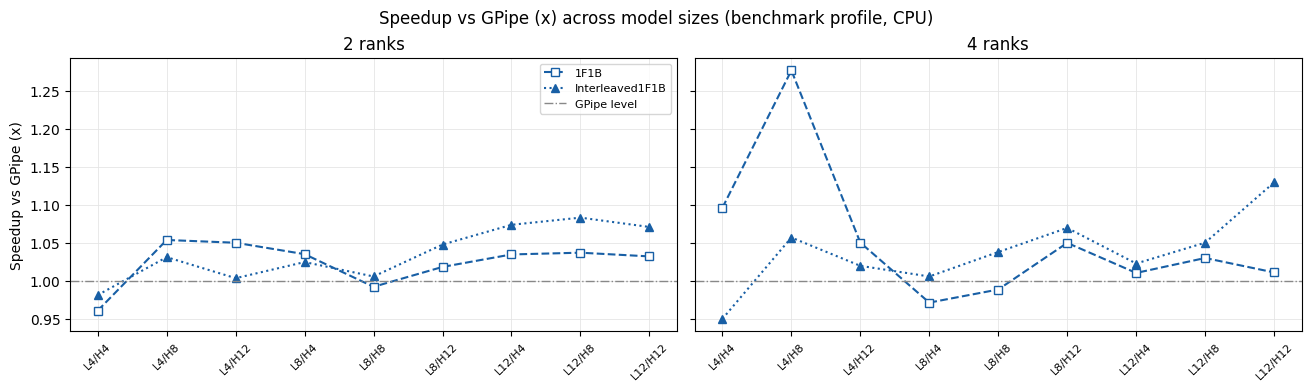

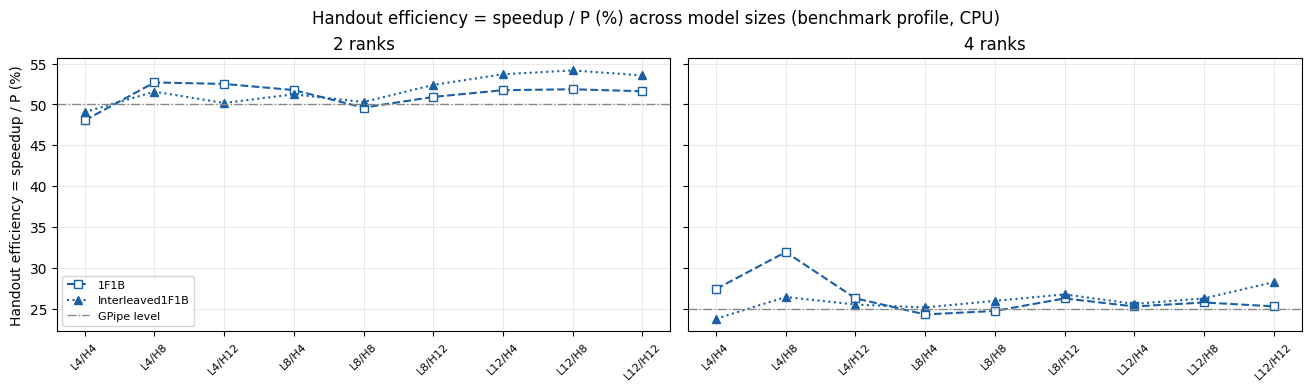

ranks              2                               4                        
schedule        1F1B   GPipe Interleaved1F1B    1F1B   GPipe Interleaved1F1B
layers heads                                                                
4      4      4873.0  5072.0          4977.0  7413.0  6763.0          6424.0
       8      5194.0  4929.0          5082.0  7392.0  5789.0          6119.0
       12     5030.0  4790.0          4807.0  6925.0  6594.0          6724.0
8      4      2739.0  2646.0          2711.0  3905.0  4021.0          4044.0
       8      2616.0  2637.0          2652.0  3895.0  3940.0          4089.0
       12     2613.0  2566.0          2689.0  3976.0  3787.0          4051.0
12     4      1861.0  1798.0          1931.0  2750.0  2722.0          2784.0
       8      1809.0  1744.0          1889.0  2703.0  2624.0          2756.0
       12     1769.0  1714.0          1836.0  2581.0  2553.0          2883.0

ranks             2                             4                       
schedule       1F1B  GPipe Interleaved1F1B   1F1B  GPipe Interleaved1F1B
layers heads                                                            
4      4      2.102  2.019           2.058  1.381  1.514           1.594
       8      1.972  2.077           2.015  1.385  1.769           1.674
       12     2.036  2.138           2.130  1.479  1.553           1.523
8      4      3.739  3.870           3.777  2.622  2.547           2.532
       8      3.914  3.883           3.861  2.629  2.599           2.504
       12     3.919  3.990           3.808  2.575  2.704           2.528
12     4      5.503  5.694           5.303  3.723  3.762           3.678
       8      5.661  5.870           5.420  3.788  3.902           3.716
       12     5.788  5.974           5.579  3.968  4.011           3.551

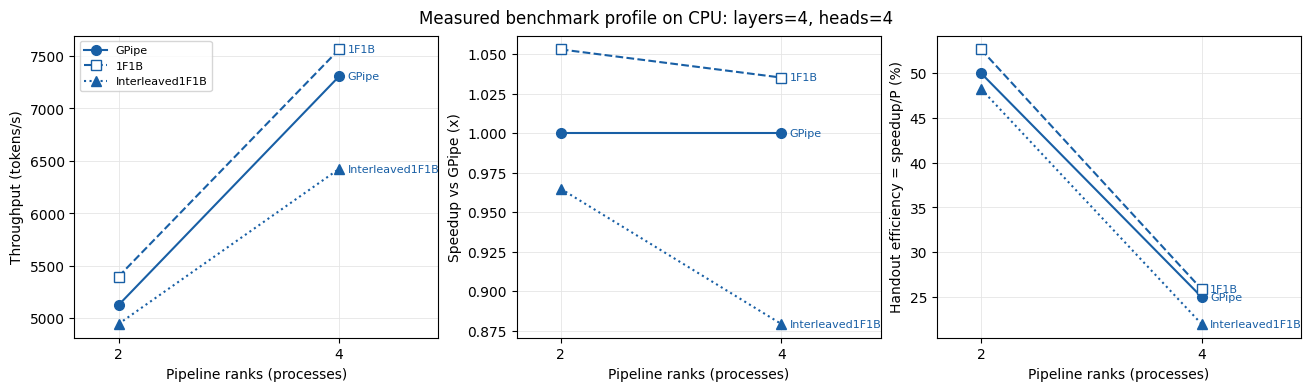

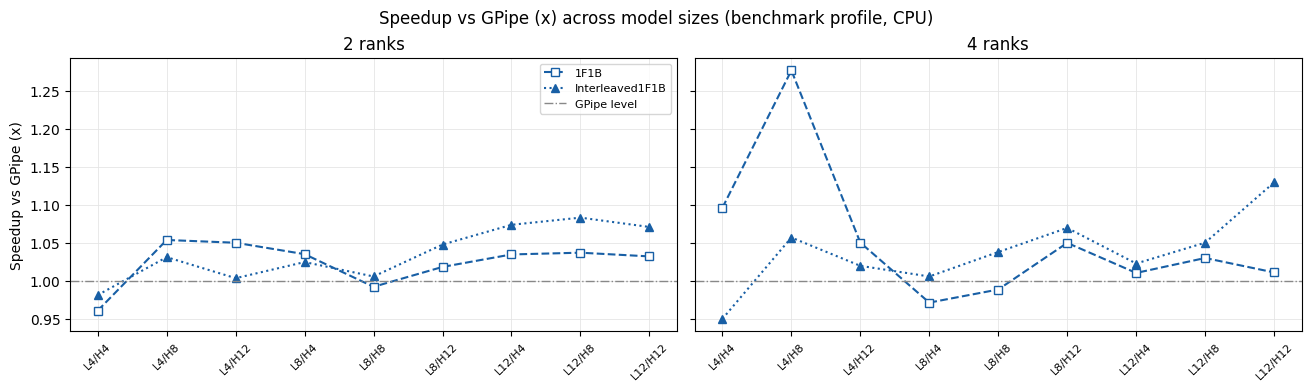

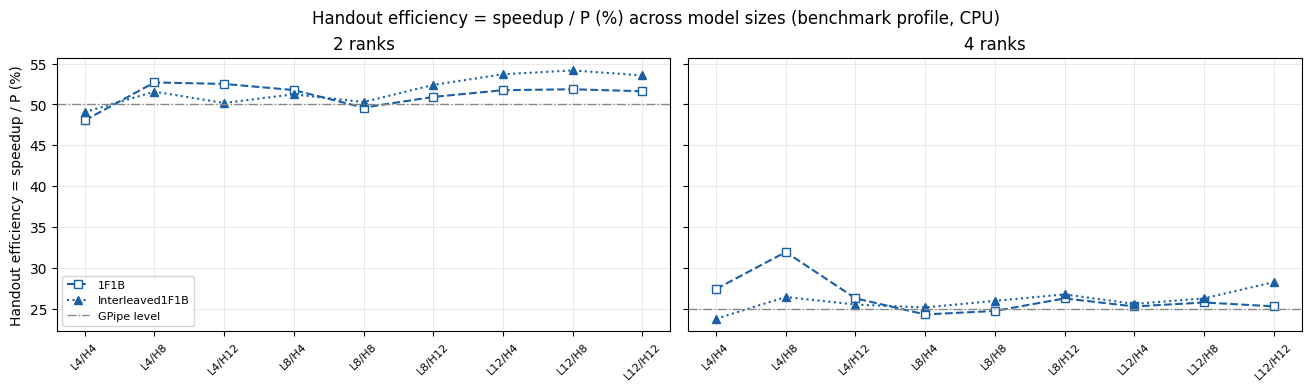

In [10]:
from IPython.display import display
rows_to_analyze = benchmark_rows if RUN_FULL_BENCHMARK else smoke_rows
summary = pipeline_tasks.summarize_results(rows_to_analyze)
print("Measured device(s):", sorted(summary.device.unique()))
display(summary[["device", "profile", "schedule", "layers", "heads", "ranks", "seconds",
                 "tokens_per_second", "gpipe_speedup", "handout_efficiency_pct"]])
result_directory = BASE / ("p1_results_benchmark" if RUN_FULL_BENCHMARK else "p1_results_smoke")
summary.to_csv(result_directory / "summary.csv", index=False)
figure = pipeline_tasks.plot_results(summary, layers=4, heads=4)
figure.savefig(result_directory / "summary.png", dpi=160, bbox_inches="tight")

# Handout plots: speedup and handout efficiency of 1F1B / Interleaved1F1B vs GPipe across all 9 model sizes
table_for_plots = median_summary if "median_summary" in globals() else summary
for name, fig in pipeline_tasks.plot_model_size_comparison(table_for_plots).items():
    fig.savefig(result_directory / f"{name}_by_model_size.png", dpi=160, bbox_inches="tight")
    display(fig)

# Pivot tables for the write-up: throughput (tokens/s) and end-to-end time for the fixed 10 iterations
display(table_for_plots.pivot_table(index=["layers", "heads"], columns=["ranks", "schedule"],
                                    values="tokens_per_second").round(0))
display(table_for_plots.pivot_table(index=["layers", "heads"], columns=["ranks", "schedule"],
                                    values="seconds").round(3))

## 5. Discussion — 2 points

Use your own measured rows to answer:
- Which schedule is fastest for each architecture/process count? Are differences
  larger than run-to-run variation? Cite table rows, units and run profile.
- How do layer count and head count change compute balance and overhead? At fixed
  width the head count does not simply multiply total attention projection FLOPs.
- Does going from two to four ranks help at this fixed global workload? Explain
  fill/drain, microbatch work size and extra communication without equating the
  handout efficiency with physical device utilization.
- Where do measured behavior and idealized bubble formulas differ? Discuss the
  embedding/head imbalance and attention/MLP half-stage imbalance explicitly.
- Which results are CPU smoke, full CPU benchmarks, or genuine GPU benchmarks, and what
  hardware/network limits prevent extrapolation?

**Result-dependent conclusions remain pending until the full experiment is run.**

**TODO:** Cite measured results and discuss the limitations above.

**Discussion (measured; full CPU benchmark profile, Gloo, 3 independent repeats of the 54-job grid; times are the median over repeats of the rank-maximum wall time for 10 iterations; source: `summary_median.csv`, `variability.csv`).**

**Which schedule is fastest, and is the difference real?**
- On median time, **Interleaved1F1B is fastest in 11 of the 18 (layers, heads, ranks) settings**, 1F1B in 6, and GPipe in 1 (L4/H4/P2).
  - Interleaving wins **all six 12-layer settings**, e.g. L12/H12/P4: 3.551 s vs GPipe 4.011 s, a speedup of 1.13×, or 2,883 vs 2,553 tokens/s.
  - 1F1B wins most 4-layer settings, e.g. L4/H8/P4: 1.385 s vs 1.769 s, a speedup of 1.28×.
- **The margins are small compared with the noise.**
  - Median GPipe-relative speedups lie between 0.95× and 1.28×, and most are within ±7%.
  - The median run-to-run spread of a configuration's time ((max−min)/median over 3 repeats) is **8.3%**: 3.9% at 2 ranks and 12.0% at 4 ranks, with a maximum of 34.5% (GPipe, L4/H8/P4).
  - Only **8/18 Interleaved1F1B and 7/18 1F1B settings were faster than the matched GPipe run in all three repeats**.
- So the ordering is consistent only for the deeper models, especially L = 12 with interleaving. For most 4-layer and 8-layer settings, the schedules are statistically indistinguishable at this sample size.

**Effect of layers and heads.**
- *Layers.* Time grows almost linearly with depth. With 2 ranks the mean time is 2.06 s, 3.86 s and 5.64 s for 4, 8 and 12 layers (1.87× and 2.74×). With 4 ranks it is 1.54 s, 2.58 s and 3.79 s. Doubling or tripling depth doubles or triples the work per stage, while per-micro-batch scheduling and Gloo latency stay fixed, so overhead becomes a smaller share of a deeper model's step time.
- *Heads.* Head count barely matters: the mean time with 2 ranks is 3.79 s, 3.85 s and 3.93 s for 4, 8 and 12 heads (+4%). At fixed width 192, the Q/K/V/output projections cost about 4d² FLOPs per token *regardless of the number of heads*; more heads only make each head smaller (48 → 24 → 16 dimensions). The score/value matmuls are about 2·seq·d per token, which is also independent of the head count. With sequence length 64 these are small next to the projections and the MLP's 8d². The slight slowdown comes from more, smaller attention kernels.

**Two → four ranks at a fixed global workload.**
- Going from 2 to 4 ranks **reduces time by 1.43× (GPipe), 1.47× (1F1B) and 1.43× (interleaved) on average** (range 1.18–1.57×), well below the 2× of perfect strong scaling. The gain is smallest for 4-layer models (1.34×) and about 1.49× for 8 and 12 layers.
- The bubble model explains part of this. The idle fraction (P−1)/(m+P−1) rises from 11.1% at P = 2 to 27.3% at P = 4 with m = 8, which caps the ideal 2→4 gain at 2 × (1−0.273)/(1−0.111) ≈ 1.64×.
- The rest comes from:
  - stage compute halving while the per-transfer latency of each micro-batch (2 sequences × 64 tokens) stays constant;
  - twice as many stage boundaries to cross;
  - four processes sharing one VM's CPU and memory bandwidth.
- The handout efficiency (speedup / P) is **not utilisation**: GPipe scores exactly 50% at P = 2 and 25% at P = 4 by construction, so the 4-rank values (about 24–32%) mainly reflect the definition, not how busy the cores were.

**Measured behaviour versus the idealised formulas.**
- *1F1B versus GPipe.* With equal stages, the formulas predict **identical bubbles** for GPipe and 1F1B, and therefore a speedup of exactly 1.0. Measured 1F1B is 1.02× faster at P = 2 and 1.05× at P = 4 on average. That is mostly within noise; 1F1B's smaller in-flight activation set (≤ P instead of m micro-batches) may also help CPU cache locality.
- *Interleaving.* The ideal interleaved speedup over GPipe is (m+P−1)/(m+(P−1)/v): **1.06× at P = 2 and 1.16× at P = 4**. Measured averages are 1.04× and 1.07×. The direction matches, a larger benefit at 4 ranks where the bubble is bigger, but the size is smaller, because each extra virtual stage adds a Gloo send/receive pair per micro-batch.
- *Stage imbalance.* The partition gives every stage the same **number** of residual units, but not the same cost.
  - An MLP unit costs about 8d² FLOPs per token, while an attention unit costs about 4d² + 2·seq·d. So an MLP half-stage is roughly 1.7× an attention half-stage.
  - Stage 0 also holds the token and position embeddings, and the last stage holds the final LayerNorm, the 192×256 output head and the loss.
  - The clearest case is **L4/P4 interleaved**: 8 stages of one unit each, so rank 0 owns attn_0 + attn_2, rank 1 owns mlp_0 + mlp_2, rank 2 owns attn_1 + attn_3, and rank 3 owns mlp_1 + mlp_3 plus the head. Ranks 1 and 3 carry about 1.7× the work of ranks 0 and 2, and the pipeline runs at the pace of the slowest rank. This is the one 4-rank setting where interleaving is **slower than GPipe** (0.95×, 1.594 s vs 1.514 s).
  - GPipe and 1F1B with L4/P4 instead give every rank one balanced (attention + MLP) pair.
  - The bubble formulas assume equal stages and free communication, so they cannot capture either effect.

**What kind of results these are, and the limits on extrapolation.**
- The 6 smoke rows are a **correctness** check only (tiny width-24 model, verified against an unpartitioned model).
- The 54 × 3 rows are a **full CPU benchmark**: valid CPU/Gloo measurements on one Colab VM, **not GPU results**. No genuine GPU benchmark was run, because the full grid needs 4 GPUs with NCCL.
- These numbers should not be extrapolated to GPUs:
  - on a GPU, compute is orders of magnitude faster while the send/receive latency of small activations becomes relatively larger;
  - NVLink or NCCL change the communication cost entirely;
  - 4 CPU processes on a shared VM compete for cores and memory bandwidth, which shows in the higher 4-rank variability (12% vs 3.9%);
  - the model is tiny (width 192, sequence 64) and runs only 10 timed iterations.
- On real multi-GPU hardware, with larger layers and more micro-batches, the bubble terms would dominate more and the interleaving benefit would likely be clearer, but this experiment does not establish that. The VM had 8 vCPUs (likely 4 physical cores with hyper-threading), so the 4 single-threaded ranks were never oversubscribed. However, they share physical cores, caches and memory bandwidth, which is a plausible cause of the higher 4-rank variability.

## Verification and submission checklist

- Run both embedded export cells; submit this completed notebook and your saved results.
  The worker and complete BSD notice are bundled here; no companion upload is required.
- Fill conceptual answers, setup/hardware notes, all graded implementations and discussion.
- Include the **54-row full benchmark** table/plots and raw measurement metadata.
  Six smoke rows are a debugging milestone, not completion of the 10-point experiment.
- Instructor check: from the repository root, run `python hw2-sol/tests/test_problem1_solution.py`.
  It validates all 54 partitions and executes three schedules on 2/4 CPU ranks,
  compares loss/gradients/SGD updates, and changes microbatch count in a targeted test.
- Cleared distributed outputs in the distributed notebooks are intentional. Execute
  your own copy to obtain authentic measurements; do not assume performance gains.

## Save runtime results

Enable the following cell to archive raw JSON, CSV and figures from both profiles. Colab downloads it; local users receive the absolute file path. Save before the runtime is deleted.


In [11]:
# Opt-in: save results before Colab deletes this ephemeral runtime.
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS:
    from zipfile import ZipFile, ZIP_DEFLATED
    archive = BASE / "p1_results.zip"
    with ZipFile(archive, "w", compression=ZIP_DEFLATED) as bundle:
        for directory in (BASE / "p1_results_smoke", BASE / "p1_results_benchmark"):
            if directory.is_dir():
                for path in sorted(directory.rglob("*")):
                    if path.is_file():
                        bundle.write(path, path.relative_to(BASE))
    print("Results archive:", archive)
    try:
        from google.colab import files
    except ImportError:
        print("Outside Colab: save the archive from the path above.")
    else:
        files.download(str(archive))
else:
    print("Results stay in", BASE, "— enable DOWNLOAD_RESULTS to archive/download them.")


Results archive: /tmp/hw2-p1-student-jgdo8f9q/p1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Third-party attribution and license

```text
PyTorch pipelining tutorial attribution

The PipelineStage / pipeline-schedule / torchrun workflow in pipeline_worker.py
and problem1_pipeline_parallelism.ipynb is adapted from the official PyTorch
pipelining tutorial, whose source is an RST document with embedded Python:
https://docs.pytorch.org/tutorials/intermediate/pipelining_tutorial.html
https://github.com/pytorch/tutorials/blob/main/intermediate_source/pipelining_tutorial.rst
Upstream license: https://github.com/pytorch/tutorials/blob/main/LICENSE
Source and license reviewed September 29, 2026. The source URLs track main;
this is not a claim of a pinned upstream release or downloadable notebook pair.

Assignment-specific changes include a causal batch-first Transformer, attention
and MLP half-stage partitioning, three schedules, an exact experiment grid,
standalone notebook export, matched metrics, and distributed parity tests.
The tutorial's BSD 3-Clause notice is retained below.

BSD 3-Clause License

Copyright (c) 2017-2022, Pytorch contributors
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.

* Neither the name of the copyright holder nor the names of its
  contributors may be used to endorse or promote products derived from
  this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"
AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE
DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE
FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL
DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR
SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER
CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,
OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE
OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
```
